  Algorithm  Hop Count  Delay  Throughput  Packet Loss     Energy
0  Dijkstra          3  12.03   85.120532     0.073966   3.089664
1      AODV         10  59.07   17.335365     0.107915  11.110279
2      OLSR          3  12.03   85.120532     0.058154   2.455096


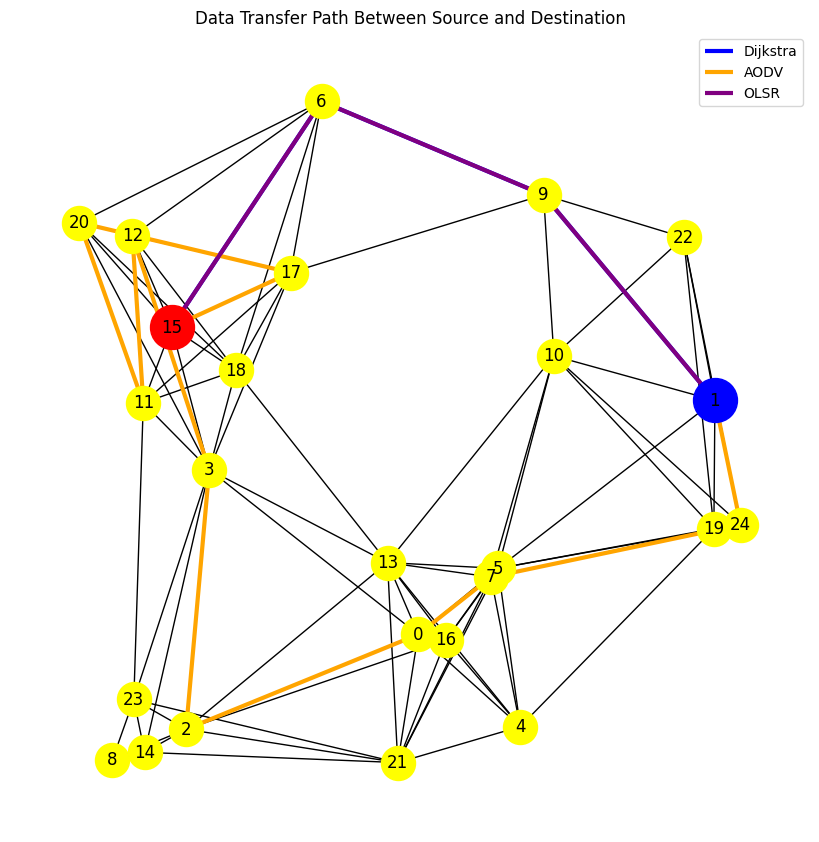

In [1]:
import networkx as nx
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt


# ============================
# Create Network
# ============================
def create_network(num_nodes=25, radius=0.4):
    G = nx.random_geometric_graph(num_nodes, radius)
    
    for u, v in G.edges():
        G[u][v]['weight'] = round(random.uniform(1, 10), 2)
        
    return G


G = create_network()
pos = nx.get_node_attributes(G, 'pos')


# ============================
# Input Source & Destination
# ============================
source = int(input("Enter source node: "))
destination = int(input("Enter destination node: "))


# ============================
# Routing Algorithms
# ============================
def dijkstra_path(G, src, dst):
    return nx.dijkstra_path(G, src, dst, weight='weight')


def aodv_path(G, src, dst):
    paths = list(nx.all_simple_paths(G, src, dst, cutoff=10))
    return random.choice(paths) if paths else None


def olsr_path(G, src, dst):
    return nx.shortest_path(G, src, dst)


# ============================
# Performance Metrics
# ============================
def compute_metrics(G, path):
    hops = len(path) - 1
    
    delay = sum(
        G[path[i]][path[i+1]]['weight']
        for i in range(hops)
    )
    
    throughput = 1024 / delay
    packet_loss = random.uniform(0.01, 0.05) * hops
    energy = hops * random.uniform(0.8, 1.2)
    
    return hops, delay, throughput, packet_loss, energy


# ============================
# Run Algorithms
# ============================
algorithms = {
    "Dijkstra": dijkstra_path,
    "AODV": aodv_path,
    "OLSR": olsr_path
}

paths = {}
results = []

for name, algo in algorithms.items():
    try:
        path = algo(G, source, destination)
        paths[name] = path
        
        hops, delay, thr, loss, energy = compute_metrics(G, path)
        
        results.append([
            name, hops, delay, thr, loss, energy
        ])
        
    except:
        paths[name] = None


# ============================
# Results Table
# ============================
df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "Hop Count",
        "Delay",
        "Throughput",
        "Packet Loss",
        "Energy"
    ]
)

print(df)


# ============================
# Visualization
# ============================
plt.figure(figsize=(8, 8))

nx.draw(
    G, pos,
    node_color='yellow',
    node_size=600,
    with_labels=True
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=[source],
    node_color='blue',
    node_size=1000
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=[destination],
    node_color='red',
    node_size=1000
)


colors = {
    "Dijkstra": "blue",
    "AODV": "orange",
    "OLSR": "purple"
}


for algo, path in paths.items():
    if path:
        
        edges = [
            (path[i], path[i+1])
            for i in range(len(path)-1)
        ]
        
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=edges,
            width=3,
            edge_color=colors[algo],
            label=algo
        )


plt.legend()
plt.title("Data Transfer Path Between Source and Destination")
plt.show()
